In [ ]:
#导入必备的工具包 
import torch
#预定义的网络层torch.nn，工具开发者已经帮助我们开发好的一些常用层，
#比如，卷积层，lstm层，embedding层，不需要我们再重新造轮子.
import torch.nn as nn
#数学计算工具包
import math
#torch中变量封装函数Variable.

from torch.autograd import Variable
#定义Embeddings类来实现文本嵌入层，这里s说明代表两个一模一样的嵌入层，他们共享参数.
#该类继承nn.Module，这样就有标准层的一些功能，这里我们也可以理解为一种模式，我们自己实现的所有月
class Embeddings(nn.Module):
    def __init__（self,d_model,vocab):
        """类的初始化函数，有两个参数，d_model：指词嵌入的维度，vocab：指词表的大小."""
        #接着就是使用super的方式指明继承nn.Module的初始化函数，我们自己实现的所有层都会这样去
        super(Embeddings,self).__init__()
        #之后就是调用nn中的预定义层Embedding，获得一个词嵌入对象self.lut 
        self.lut = nn.Embedding（vocab,d_model)
        #最后就是将d_model传入类中 
        self.d_model = d_model

    def forward(self，x):
        """可以将其理解为该层的前向传播逻辑，所有层中都会有此函数
        当传给该类的实例化对象参数时，自动调用该类函数
        参数x：因为Embedding层是首层，所以代表输入给模型的文本通过词汇映射后的张量"""
        #将x传给self.lut并与根号下self.d_model相乘作为结果返回 
        return self.lut(x) * math.sqrt(self.d_model)






        

In [ ]:
#定义位置编码器类，我们同样把它看做一个层，因此会继承nn.Module 
class PositionalEncoding(nn.Module):
    def __init__(self,d_model,dropout,max_len=5000):
        """位置编码器类的初始化函数，共有三个参数，分别是d_model：词嵌入维度， dropouf：置θ比率，max_len：每个句子的最大长度"""
        super(PositionalEncoding,self).__init__()
        #实例化nn中预定义的Dropout层，并将dropout传入其中，获得对象self.dropout 
        self.dropout = nn.Dropout(p=dropout)
        #实例化nn中预定义的Dropout层，并将dropout传入其中，获得对象self.dropout 
        #self.dropout = nn.Dropout(p=dropout)
        
        #初始化一个位置编码矩阵，它是一个o阵，矩阵的大小是max_len×d_model. pe = torch.zeros(max_len,d_model)
        #初始化一个绝对位置矩阵，在我们这里，词汇的绝对位置就是用它的索引去表示，
        #所以我们首先使用arange方法获得一个连续自然数向量，然后再使用unsqueeze方法拓展向量维度
        #又因为参数传的是1，代表矩阵拓展的位置，会使向量变成一个max_lenx1的矩阵， 
        position =torch.arange(0,max_len).unsqueeze（1)
        #绝对位置矩阵初始化之后，接下来就是考虑如何将这些位置信息加入到位置编码矩阵中，
        #最简单思路就是先将max_lenx1的绝对位置矩阵，变换成max_lenxd_model形状，然后覆
        #要做这种矩阵变换，就需要一个1xd_model形状的变换矩阵div_term，我们对这个变换矩阵的要习
        #还希望它能够将自然数的绝对位置编码缩放成足够小的数字，有助于在之后的梯度下降过程中更快的
        #首先使用arange获得一个自然数矩阵，但是细心的同学们会发现，我们这里并没有按照预计的
        #而是有了一个跳跃，只初始化了一半即1xd_mode1/2的矩阵。为什么是一半呢，其实这里并不是
        #我们可以把它看作是初始化了两次，而每次初始化的变换矩阵会做不同的处理，第一次初始化的变换
        #并把这两个矩阵分别填充在位置编码矩阵的偶数和奇数位置上，组成最终的位置编码矩阵. 
        div_term =torch.exp（torch.arange（0,d_model，2）* -（math.1og（10000.0)/d_mode1))

        pe[:,0::2]=torch.sin(position *div_term) 
        pe[:,1::2]=torch.cos(position *div_term)
        #这样我们就得到了位置编码矩阵pe，pe现在还只是一个二维矩阵，要想和embedding的输出（一个
        #就必须拓展一个维度，所以这里使用unsqueeze拓展维度
        #这样我们就得到了位置编码矩阵pe，pe现在还只是一个二维矩阵，要想和embedding的输出（一个
        #就必须拓展一个维度，所以这里使用unsqueeze拓展维度. 
        pe = pe.unsqueeze(0)
        
        #最后把pe位置编码矩阵注册成模型的buffer，什么是buffer呢，
        #我们把它认为是对模型效果有帮助的，但是却不是模型结构中超参数或者参数，不需要随着优化步骤
        #注册之后我们就可以在模型保存后重加载时和模型结构与参数一同被加载， 
        self.register_buffer('pe',pe)
    def forward(self，x):
        """forward函数的参数是x，表示文本序列的词嵌入表示"""
        #在相加之前我们对pe做一些适配工作，将这个三维张量的第二维也就是句子最大长度的那一维将
        #因为我们默认max_1en为5000一般来讲实在太大了，很难有一条句子包含5000个词汇，所以要进
        #最后使用Variable进行封装，使其与x的样式相同，但是它是不需要进行梯度求解的，因此把req 
        x=x+Variable(self.pe[:，:x.size（1)],requires_grad=False)
        #最后使用self.dropout对象进行'丢弃操作，并返回结果， 
        return self.dropout(x)
        

In [1]:
#2.2-part1

import torch
import torch.nn as nn #包含卷积层，lstm层，embedding层等
import torch.nn.functional as F
from torch.autograd import Variable 
import math
import matplotlib.pyplot as plt
import numpy as np 
import copy

In [2]:
import torch.nn as nn
#数学计算工具包 
import math
#torch中变量封装函数Variable.
from torch.autograd import Variable
#定义Embeddings类来实现文本嵌入层，这里s说明代表两个一模一样的嵌入层，他们共享参数
#该类继承nn.Module，这样就有标准层的一些功能，这里我们也可以理解为一种模式，我们自己实现的所有层
class Embeddings(nn.Module):
    def __init__(self,d_model,vocab):
        """类的初始化函数，有两个参数，d_model：指词嵌入的维度，vocab：指词表的大小."""
        #接着就是使用super的方式指明继承nn.Module的初始化函数，我们自己实现的所有层都会这样去 
        super(Embeddings,self).__init__()
        #之后就是调用nn中的预定义层Embedding，获得一个词嵌入对象self.lut 
        self.lut = nn.Embedding(vocab,d_model)
        #最后就是将d_model传入类中 
        self.d_model = d_model
    def forward(self,x):
        """可以将其理解为该层的前向传播逻辑，所有层中都会有此函数
        当传给该类的实例化对象参数时，自动调用该类函数
        参数x：因为Embedding层是首层，所以代表输入给模型的文本通过词汇映射后的张量"""
        #将x传给self.lut并与根号下self.d_model相乘作为结果返回 
        return self.lut(x) * math.sqrt(self.d_model)  #对词表向量有个缩放的作用

In [3]:
#构建Embedding类来实现文本嵌入层 
class Embeddings(nn.Module):
    def __init__(self,d_model,vocab):
        #d_model：词嵌入的维度#vocab：词表的大小
        super(Embeddings,self).__init__()#定义Embedding层
        self.lut =nn.Embedding(vocab,d_model) #将参数传入类中
        self.d_model=d_model
    def forward(self,x):
        #X：代表输入进模型的文本通过词汇映射后的数字张量 
        return self.lut(x)* math.sqrt(self.d_model)

In [4]:
#测试embedding
embedding = nn.Embedding(10,3) # 8表示输入张量的最大值。3表示使用多少个维度表示一个词
input1=torch.LongTensor([[1,2,4,5],[4,3,2,9]])
embedding(input1)


tensor([[[ 0.3493, -1.1144, -0.0585],
         [-0.1764, -0.1482,  2.2152],
         [-0.9880, -1.4812,  0.6597],
         [-1.5781, -0.2642, -1.6374]],

        [[-0.9880, -1.4812,  0.6597],
         [-1.0191, -0.1479, -0.4286],
         [-0.1764, -0.1482,  2.2152],
         [ 1.2655,  0.2090, -1.2467]]], grad_fn=<EmbeddingBackward0>)

In [5]:
embedding =nn.Embedding(10,3,padding_idx=0) #padding_idx : 表示如果是0，使用全0数值的向量
input1 =torch.LongTensor([[0,2,0,5]])
embedding(input1)

tensor([[[ 0.0000,  0.0000,  0.0000],
         [ 0.7200, -0.1007,  0.2473],
         [ 0.0000,  0.0000,  0.0000],
         [-1.5067,  0.9097,  0.5646]]], grad_fn=<EmbeddingBackward0>)

In [ ]:
#芯片股：
"""中芯国际；华虹半导体；"""


In [6]:
#2.2-part2
#演示 Embeddings 类的使用
d_model=512 
vocab =1000
x=Variable(torch.LongTensor([[100,2,421,508],[491,998,1,221]]))
emb =Embeddings(d_model,vocab)
embr= emb(x)
print("embr:",embr) 
print(embr.shape)

embr: tensor([[[ 27.6197, -13.8910,   4.7150,  ..., -18.3769, -15.7475, -23.8114],
         [ -8.7753,  17.7920,   4.5785,  ...,   8.0703,   5.9872, -17.0923],
         [  5.9172,  -5.5882,  -1.8294,  ...,  -9.8444, -51.3587,  13.4831],
         [  7.1501,  36.6963,  30.6412,  ...,  -1.0549, -27.6783, -21.5690]],

        [[-17.6820,  27.2569,   5.4603,  ..., -26.5257,  25.7437,  21.1703],
         [ 17.2717, -36.1770, -18.3961,  ...,  -1.1545,   7.0089,  21.8685],
         [-32.0536, -12.9261,  12.2718,  ..., -46.1827, -21.6131,  17.6532],
         [ -6.4178,  13.8233, -30.6571,  ..., -10.9835,  -9.8276,   0.5698]]],
       grad_fn=<MulBackward0>)
torch.Size([2, 4, 512])


In [7]:
#2.2-part3 part4
#位置编码的作用
#构建位置编码器的类
class PositionalEncoding(nn.Module):
    def __init__(self,d_model,dropout,max_len=5000):
        #d_model：代表词嵌入的维度
        #dropout：代表Dropout层的置零比率
        #max_Len：代表每隔句子的最大长度
        super(PositionalEncoding,self).__init__()
        #实例化Dropout层
        self.dropout=nn.Dropout(p=dropout)
        #初始化一个位置编码矩阵，大小是max_len*d_model
        pe = torch.zeros(max_len,d_model)
        #初始化一个绝对位置矩阵，max_len*1
        position = torch.arange(0,max_len).unsqueeze(1)
        #定义一个变化矩阵div_term，跳跃式的初始化
        div_term =torch.exp(torch.arange(0,d_model,2)* (-(math.log(10000.0) / d_model)))
        #将前面定义的变化矩阵进行奇数，偶数的分别赋值
        pe[:,0::2]= torch.sin(position * div_term)
        pe[:,1::2]=torch.cos(position * div_term)

        #将二维张量扩充成三维张量 
        pe =pe.unsqueeze(0)
        #将位置编码矩阵注册成模型的buffer，这个buffer不是模型中的参数，不跟随优化器同步更新
        #注册成buffer后我们就可以在模型保存后重新加载的时候，将这个位置编码器和模型参数一同加载进来
        self.register_buffer('pe',pe)


        #max_len 对应的那个维度缩小成x的句子长度同等的长度，位置编码不参与更新
    def forward(self,x):
        #X：代表文本序列的词嵌入表示
        #首先明确pe的编码太长了，将第二个维度，也就是max_len 对应的那个维度缩小成x的句子长度同等的长度，位置编码不参与更新
        x=x+Variable(self.pe[:,:x.size(1)],requires_grad=False)
        return self.dropout(x)

In [9]:
#nn.Dropout演示
m=nn.Dropout(p=0.2)
input=torch.randn(4,5)
output = m(input)
output

tensor([[-1.7183,  1.1681, -1.4457, -0.0109,  0.0000],
        [-0.3388, -2.9859,  0.9200,  0.6298, -0.3593],
        [-2.4750, -0.4765, -0.3430,  2.6934, -0.0000],
        [ 0.3280,  0.3487, -1.3056,  0.0000, -0.0000]])

In [10]:
#torch.unsqueeze演示：
x=torch.tensor([[1,2,3,4],[4,5,6,7]])
t = torch.unsqueeze(x,1) #在行上增加维

# torch.unsqueeze(x,1)  #在列上增加维

In [11]:
#演示
d_model=512 
dropout=0.1 
max_len = 60
x=embr
pe = PositionalEncoding(d_model, dropout,max_len)
pe_result=pe(x)
print(pe_result) #经过位置编码后的结果
print(pe_result.shape)

tensor([[[ 30.6886, -14.3233,   5.2389,  ..., -19.3076, -17.4972, -25.3459],
         [ -8.8154,  20.3692,   6.0004,  ...,  10.0781,   0.0000, -17.8804],
         [  7.5850,  -6.6715,  -0.9922,  ...,  -9.8272, -57.0650,  16.0923],
         [  8.1014,  39.6737,  34.3181,  ...,  -0.0610,  -0.0000, -22.8544]],

        [[-19.6467,  31.3965,   6.0670,  ..., -28.3619,  28.6041,  24.6337],
         [ 20.1257, -39.5963, -19.5270,  ...,  -0.1716,   7.7877,   0.0000],
         [-34.6047, -14.8248,  14.6758,  ..., -50.2030, -24.0143,  20.7258],
         [ -6.9741,  14.2593, -33.7911,  ...,  -0.0000, -10.9192,   1.7443]]],
       grad_fn=<MulBackward0>)
torch.Size([2, 4, 512])


In [ ]:
2,4,512
60,512

x

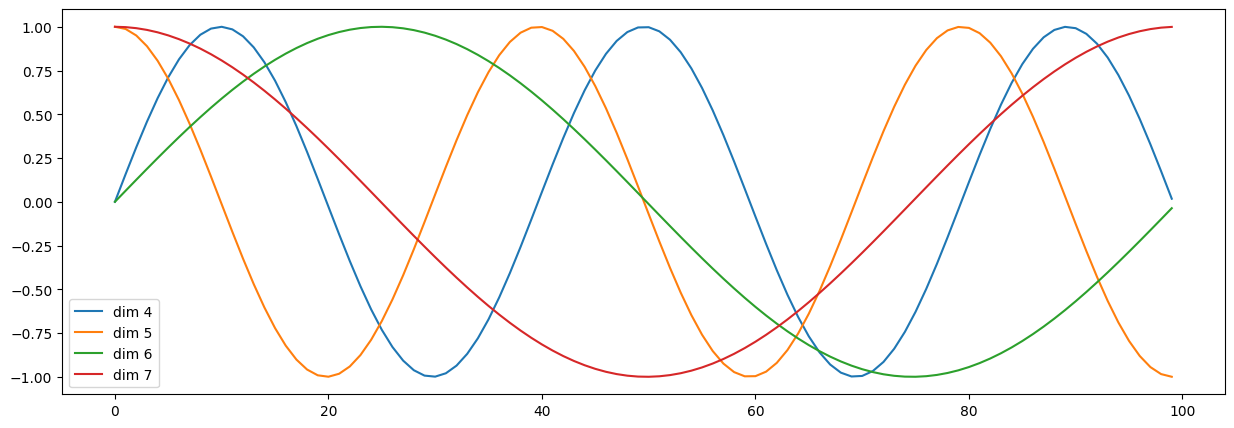

In [12]:
#2.2 -part5
#图形化展示：
import matplotlib.pyplot as plt
#创建一张15×5大小的画布
plt.figure(figsize=(15,5))
#实例化PositionalEncoding类得到pe对象，输入参数是20和0 
pe = PositionalEncoding(20,0)
#然后向pe传入被Variable封装的tensor，这样pe会直接执行forward函数，
#且这个tensor里的数值都是0，被处理后相当于位置编码张量 
y= pe(Variable(torch.zeros(1,100,20)))
#然后定义画布的横纵坐标，横坐标到100的长度，纵坐标是某一个词汇中的某维特征在不同长度下对应的值
#因为总共有20维之多，我们这里只查看4，5，6，7维的值，
plt.plot(np.arange(100),y[0,:,4:8].data.numpy())#在画布上填写维度提示信息
plt.legend(["dim %d"%p for p in [4,5,6,7]])


In [ ]:
#2.2 -part6对 2.2章的总结

In [13]:
#2.3.1 -part1 掩码张量
def subsequent_mask(size):
    """生成向后遮掩的掩码张量，参数ize是掩码张量最后两个维度的大小，它的最后两维形成一个方阵"""
    #在函数中，首先定义掩码张量的形状 
    attn_shape =(1,size,size)
    #然后使用np.ones方法向这个形状中添加1元素，形成上三角阵，最后为了节约空间，
    #再使其中的数据类型变为无符号8位整形unit8
    subsequent_mask = np.triu(np.ones(attn_shape),k=1).astype('uint8')
    #最后将numpy类型转化为torch中的tensor，内部做一个1-的操作，
    #在这个其实是做了一个三角阵的反转，subsequent_mask中的每个元素都会被1减，
    #如果是0，subsequent_mask中的该位置由o变成1#如果是1，subsequent_mask中的该位置由1变成0
    return torch.from_numpy(1 - subsequent_mask)

In [ ]:
#2.3.1 part2构建掩码张量的函数
#测试掩码的作用
print(np.triu([[1,2,3],[4, 5,6],[7,8,9],[10, 11, 12]],k=-1))
print(np.triu([[1,2,3],[4,5,6],[7,8,9],[10,11,12]],k=0))

In [14]:

def subsequent_mask(size):
    #size：代表掩码张量后两个维度，形成一个方阵 
    attn_shape =(1, size, size)
    #使用np.ones（）先构建一个全1的张量，然后利用np。triu（）形成上三角矩阵
    subsequent_mask=np.triu(np.ones(attn_shape),k=1).astype('uint8')
    
    #使得这个三角矩阵反转
    return torch.from_numpy(1- subsequent_mask)

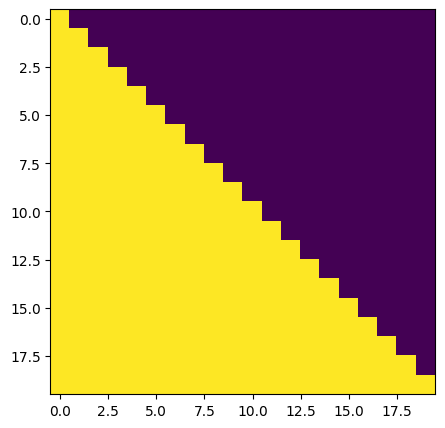

In [15]:
size =5
sm = subsequent_mask(size)
#print("sm:"，sm)
plt.figure(figsize=(5,5))
plt.imshow(subsequent_mask(20)[0])

In [ ]:
#2.3.1 -part3 掩码张量总结（略）


In [ ]:
#2.3.2 -part1 注意力机制解释
#2.3.2 -part2 注意力机制代码分析
#2.3.2 -part3 注意力机制代码编写

#演示mask_fill
x=Variable(torch.randn(5,5))
# print(x)
mask=Variable(torch.ones(5,5)) 
mask = torch.from_numpy(np.triu(mask))
print(mask)

y=x.masked_fill(mask==0,-1e9) 
print(x)
print(y)

In [20]:
print(f"PyTorch版本: {torch.__version__}")

PyTorch版本: 2.8.0+cpu


In [38]:
#2.3.2 -part3 注意力机制代码分析
def attention(query,key,value,mask=None,dropout=None):
    #query，key，value：代表注意力的三个输入张量
    #mask：掩码张量
    #dropout：传入的Dropout实例化对象
    #首先将query的最后一个维度提取出来，代表的是词嵌入的维度 
    d_k=query.size(-1)
    #按照注意力计算公式，将query和key的转置进行矩阵乘法，然后除以缩放稀疏
    scores =torch.matmul(query,key.transpose(-2,-1))/ math.sqrt(d_k)
    #判断是否使用掩码张量 
    if mask is not None:
        #利用masked_filL方法，将掩码张量和0进行位置的意义比较，如果等于O，替换成一个非常小的数值
        #print(query.shape,key.shape,value.shape,scores.shape,mask.shape)
        scores =scores.masked_fill(mask==0,-1e9)
    #对scores的最后一个维度上进行softmax操作
    p_attn =F.softmax(scores, dim=-1)
    #判断是使用dropout
    if dropout is not None:
        p_attn = dropout(p_attn)
    #最后一步完成p_attn和value张量的乘法，并返回query注意力表示 
    return torch.matmul(p_attn,value),p_attn


In [36]:
query=key=value=pe_result
mask = Variable(torch.zeros(2,4,4))
attn,p_attn = attention(query,key,value,mask=mask)
print('attn',attn)
print(attn.shape)
print('p_attn:',p_attn)
print(p_attn.shape)

torch.Size([2, 4, 512]) torch.Size([2, 4, 512]) torch.Size([2, 4, 512]) torch.Size([2, 4, 4]) torch.Size([2, 4, 4])
attn tensor([[[  9.3899,   9.7620,  11.1413,  ...,  -4.7794, -18.6405, -12.4971],
         [  9.3899,   9.7620,  11.1413,  ...,  -4.7794, -18.6405, -12.4971],
         [  9.3899,   9.7620,  11.1413,  ...,  -4.7794, -18.6405, -12.4971],
         [  9.3899,   9.7620,  11.1413,  ...,  -4.7794, -18.6405, -12.4971]],

        [[-10.2750,  -2.1913,  -8.1438,  ..., -19.6841,   0.3646,  11.7759],
         [-10.2750,  -2.1913,  -8.1438,  ..., -19.6841,   0.3646,  11.7759],
         [-10.2750,  -2.1913,  -8.1438,  ..., -19.6841,   0.3646,  11.7759],
         [-10.2750,  -2.1913,  -8.1438,  ..., -19.6841,   0.3646,  11.7759]]],
       grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 4, 512])
p_attn: tensor([[[0.2500, 0.2500, 0.2500, 0.2500],
         [0.2500, 0.2500, 0.2500, 0.2500],
         [0.2500, 0.2500, 0.2500, 0.2500],
         [0.2500, 0.2500, 0.2500, 0.2500]],

        [[0.250

In [ ]:
#2.3.2 -part4 注意力机制总结

x=torch.randn(4,4)
print(x.size())
y=x.view(16)
print(y.size())
z=x.view(-1,8)
print(z.size())

a=torch.randn(1,2,3,4)
print(a.size())
print(a)
b=a.transpose(1,2)
print(b.size())
print(b)
c=a.view(1,3,2,4)
print(c.size())
print(c)

In [34]:
#2.3.3 -part1 多头注意力机制介绍
#2.3.3 -part2 多头注意力机制代码讲解
#2.3.3 -part3 多头注意力机制代码编辑

#实现克隆函数，因为在多头注意力机制下，要用到多个结构相同的线性层
#需要使用cLone函数将他们一同初始化到一个网络层列表对象中 
def clones(module,N):
    #module：代表要克隆的目标网络层#N：将module克隆几个
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])

#实现多头注意力机制的类
class MultiHeadedAttention(nn.Module):
    def __init__(self,head,embedding_dim,dropout=0.1):
        #head：代表几个头的参数
        #embedding_dim：代表词嵌入的维度
        #dropout：进行Drorout操作时，置零的比率
        super(MultiHeadedAttention,self).__init__()
        #要确认一个事实：多头的数量head需要整除词嵌入的维度embedding_dim
        assert embedding_dim%head==0
        #得到每个头获得的词向量的维度
        self.d_k=embedding_dim//head 
        self.head=head
        self.embedding_dim=embedding_dim
        #获得线性层，要获得4个，分别是Q，K，V以及最终的输出线性层
        self.linears=clones(nn.Linear(embedding_dim,embedding_dim),4)
        #初始化注意力张量 
        self.attn = None
        #初始化dropout对象
        self.dropout=nn.Dropout(p=dropout)

    def forward(self,query,key,value,mask=None):
        #query，key，value是注意力机制的三个输入张量，mask代表掩码张量
        #首先判断是否使用掩码张量 
        if mask is not None:
            #使用squeeze将掩码张量进行维度扩充，代表多头中的第n个头 
            mask=mask.unsqueeze(1)
        #得到batch_size
        batch_size = query.size(0)
        #首先使用zip将网络层和输入数据连接在一起，模型的输出利用view和transpose进行维度和形状的改变
        query,key,value=\
            [model(x).view(batch_size,-1,self.head, self.d_k).transpose(1,2) for model,x in zip(self.linears,(query,key,value))]
        #将每个头的输出传入到注意力层
        x,self.attn =attention(query,key,value,mask=mask,dropout=self.dropout)

        #得到每个头的计算结果是4维张量，需要进行形状的转换
        #前面已经将1，2两个维度进行过转置，在这里要重新转置回来
        #注意：经历了transpose（）方法后，必须要使用contiguous方法，不然无法使用view（）方法 
        x=x.transpose(1,2).contiguous().view(batch_size,-1,self.head * self.d_k)

        #最后将x输入线性层列表中的最后一个线性层中进行处理，得到最终的多头注意力结构输出 
        return self.linears[-1](x)

In [37]:
#2.3.3 -part4 多头注意力机制代码编辑
#实例化若于参数 
head =8
embedding_dim =512 
dropout=0.2
#若干输入参数的初始化
query = key = value = pe_result 
mask=Variable(torch.zeros(2,4,4))

mha = MultiHeadedAttention(head,embedding_dim,dropout)
mha_result=mha(query,key,value,mask)
# mha_result=mha(query,key,value) #,mask)
print(mha_result)
print(mha_result.shape)

torch.Size([2, 8, 4, 64]) torch.Size([2, 8, 4, 64]) torch.Size([2, 8, 4, 64]) torch.Size([2, 8, 4, 4]) torch.Size([2, 1, 4, 4])
tensor([[[ 3.8324, -1.9132, -3.9612,  ..., -3.3910, -3.5916,  4.5269],
         [ 3.5241, -6.0408, -2.7751,  ..., -2.4882, -8.0983,  0.6277],
         [ 3.0097, -2.9132,  1.0800,  ..., -5.6063, -4.4601,  4.7885],
         [ 6.0812, -4.7656,  0.2181,  ..., -3.4088, -8.1198,  4.5887]],

        [[-7.2845, -3.7735, -2.3281,  ..., -0.8236, -8.6282, -5.9016],
         [-4.2875, -1.1681, -0.6776,  ..., -2.6137, -9.5401, -0.0351],
         [-8.5390, -1.6121, -1.8251,  ...,  0.2395, -9.1836, -4.0962],
         [-7.2961, -2.7941,  1.5680,  ..., -0.4741, -6.4662, -3.8702]]],
       grad_fn=<ViewBackward0>)
torch.Size([2, 4, 512])


In [159]:
print(query.shape)
print(key.shape)
print(value.shape)

torch.Size([2, 4, 512])
torch.Size([2, 4, 512])
torch.Size([2, 4, 512])


In [ ]:
#构建前馈全连接网络类
class PositionwiseFeedForward(nn.Module):
    def __init__(self,d_model,d_ff，dropout=0.1):
        #d_model：代表词嵌入的维度，同时也是两个线性层的输入维度和输出维度
        #d_ff：代表第一个线性层的输出维度，和第二个线性层的输入维度#dropout：经过Dropout层处理时，随机置零的比率
        super(PositionwiseFeedForward,self).__init__())
        #定义两层全连接的线性层
        #定义两层全连接的线性层
        self.w1 =nn.Linear(d_model,d_ff) 
        self.w2=nn.Linear(d_ff,d_model) 
        self.dropout=nn.Dropout(p=dropout)
    def forward(self,x):
        #x：代表来自上一层的输出
        #首先将x送入第一个线性层网络，然后经历relu函数的激活，再经历dropout层的处理
        #最后送入第二个线性层
        return self.w2(self.dropout(F.relu(self.w1(x))))

In [ ]:
d_model=512 
d_ff=64
dropout=0.2 
x=mha_result
ff=PositionwiseFeedForward(d_model,d_ff，dropout)
ff_result=ff(x)
print(ff_result)
print(ff_result.shape)

In [10]:
#构建规范化层的类
class LayerNorm(nn.Module):
    def __init__(self,features,eps=1e-6):
        #features：代表词嵌入的维度
        #eps：一个足够小的正数，用来在规范化计算公式的分母中，防止除零操作 
        super(LayerNorm,self).__init__()
        #初始化两个参数张量a2，b2，用于对结果做规范化操作计算
        #将其用nn.Parameter进行封装，代表他们

        #初始化两个参数张量a2，b2，用于对结果做规范化操作计算
        #将其用nn.Parameter进行封装，代表他们也是模型中的参数
        self.a2=nn.Parameter(torch.ones(features)) 
        self.b2 =nn.Parameter(torch.zeros(features))
        self.eps = eps
    def forward(self,x):
        #X：代表上一层网络的输出
        #首先对x进行最后一个维度上的求均值操作，同时操持输出维度和输入维度一致 
        mean =x.mean(-1,keepdim=True)
        #接着对x进行字后一个维度上的求标准差的操作，同时保持输出维度和输入维度一致
        std =x.std(-1,keepdim=True)
        #按照规范化公式进行计算并返回
        return self.a2 *(x-mean)/(std+ self.eps)+self.b2

In [ ]:
features=d_model=512 
eps=1e-6
x=ff_result
ln=LayerNorm(features,eps)
ln_result=ln(x)
print(ln_result)
print(ln_result.shape)

In [ ]:
#构建子层连接结构的类
class SublayerConnection(nn.Module):
    def __init__(self,size,dropout=0.1):
        #size：代表词嵌入的维度
        #dropout：进行Dropout操作的置零比率
        super(SublayerConnection,self).__init__()
        #实例化一个规范化层的对象
        self.norm =LayerNorm(size)
        #实例化一个dropout对象
        self.dropout=nn.Dropout(p=dropout) 
        self.size =size
    def forward(self,x,sublayer):
        #X：代表上一层传入的张量
        #sublayer：该子层连接中子层函数
        #首先将x进行规范化，然后送入子层函数中处理，处理结果进入dropout层，最后进行残差连接
        return x+self.dropout(sublayer(self.norm(x)))

In [ ]:
size=d_model=512
head=8
dropout=0.2

In [ ]:
x=pe_result
mask=Variable(torch.zeros(8,4,4))
self_attn=MultiHeadedAttention(head,d_model)

sublayer =lambda x:self_attn(x，x，x,mask) 
sc=SublayerConnection(size,dropout)
sc_result=sc(x，sublayer) 
print(sc_result)
print(sc_result.shape)

In [11]:
#构建编码器层的类
class EncoderLayer(nn.Module):
    def __init__(self,size,self_attn,feed_forward,dropout):
        #size：代表词嵌入的维度
        #self_attn：代表传入的多头自注意力子层的实例化对象#feed_forward：代表前馈全连接层实例化对象
        #dropout：进行dropout操作时的置零比率 
        super(EncoderLayer,self).__init__()
        #将两个实例化对象和参数传入类中 
        self.self_attn = self_attn
        self.feed_forward=feed_forward 
        self.size = size
        #编码器层中有2个子层连接结构，使用clones函数进行操作
        self.sublayer=clones(SublayerConnection(size,dropout),2)

    def forward(self,x,mask):
        #X：代表上一层的传入张量#mask：代表掩码张量
        #首先让x经过第一个子层连接结构，内部包含多头自注意力机制子层#再让张量经过第二个子层连接结构，其中包含前馈全连接网络
        x=self.sublayer[0](x,lambda x:self.self_attn(x,x,x,mask))
        return self.sublayer[1](x,self.feed_forward)

In [ ]:
size=d_model=512
head=8 
d_ff=64
x=pe_result 
dropout=0.2

self_attn =MultiHeadedAttention(head,d_model)
ff=PositionwiseFeedForward(d_model,d_ff,dropout)
mask=Variable(torch.zeros(8,4,4))

el=EncoderLayer(size,self_attn,ff,dropout)
el_result=el(x,mask)
print(el_result)
print(el_result.shape)

In [12]:
#构建编码器类Encoder
class Encoder(nn.Module):
    def __init__(self,layer,N):
        #Layer：代表编码器层
        #N：代表编码器中有几个Layer
        super(Encoder,self).init()
        #首先使用cLones函数克隆N个编码器层放置在self.layers中 
        self.layers =clones(layer,N)
        #初始化一个规范化层，作用在编码器的最后面 
        self.norm=LayerNorm(layer.size)
    def forward(self,x,mask):
        #X：代表上一层输出的张量#mask：代表掩码张量
        #让x依次经历N个编码器层的处理，最后再经过规范化层就可以输出了 
        for layer in self.layers:
            x=layer(x,mask) 
        return self.norm(x)

In [ ]:
size=d_model=512
d_ff=64 head=8
c=copy.deepcopy
attn =MultiHeadedAttention(head,d_model)
ff=PositionwiseFeedForward(d_model,d_ff，dropout) 
dropout=0.2
layer=EncoderLayer（size,c（attn),c（ff),dropout） 
N=8
mask=Variable(torch.zeros(8,4,4))

en=Encoder(layer,N) 
en_result=en(x,mask) 
print(en_result)
print(en_result.shape)

In [ ]:
#2_4_1解码器层-part2
#构建解码器层类
class DecoderLayer(nn.Module):
    def __init__(self,size,self_attn,src_attn,feed_forward,dropout):
        #size：代表词嵌入的维度
        #self_attn：代表多头自注意力机制的对象
        #src_attn：代表常规的注意力机制的对象
        #feed_forward：代表前馈全连接层的对象
        #dropout：代表Dropout的置零比率
        super(DecoderLayer,self)._init_()
        #将参数传入类中 self.size=size
        self.self_attn =self_attn 
        self.src_attn = src_attn
        self.feed_forward=feed_forward 
        self.dropout=dropout
        #按照解码器层的结构图，使用clones函数克隆3个子层连接对象
        self.sublayer=clones(SublayerConnection(size,dropout),3)

    def forward(self,x,memory,source_mask,target_mask):
        #X：代表上一层输入的张量
        #memory：代表编码器的语义存储张量#source_mask：源数据的掩码张量#target_mask：目标数据的掩码张量 
        m=memory
        #第一步让x经历第一个子层，多头自注意力机制的子层
        #采用target_mask，为了将解码时未来的信息进行遮掩，比如模型解码第二个字符，只能看见第一个字符信息 
        x= self.sublayer[0](x, lambda x: self.self_attn(x,x,x,target_mask))
        #第二步让x经历第二个子层，常规的注意力机制的子层，Q！=K=V
        #采用source_mask，为了遮掩掉对结果信息无用的数据
        x=self.sublayer[1](x,lambda x:self.src_attn(x,m,m,source_mask))
            #第三步让x经历第三个子层，前馈全连接层
        return self.sublayer[2](x,self.feed_forward)
        

In [ ]:
size=d_model=512
head=8 
d_ff=64
dropout=0.2
sef_attn = src_attn = MultiHeadedAttention(head,d_model,dropout) 
ff=PositionwiseFeedForward（d_model，d_ff，dropout)

x=pe_result
memory=en_result
mask=Variable（torch.zeros（8,4,4)) 
source_mask=target_mask=mask

dl=DecoderLayer(size,self_attn,src_attn,ff,dropout)
dl_result=dl(x,memory,source_mask, target_mask) 
print(dl_result)
print(dl_result.shape)

In [ ]:
#构建解码器类
class Decoder(nn.Module):
    def __init__(self,layer,N):
        #layer：代表解码器层的对象
        #N：代表将Layer进行几层的拷贝
        super(Decoder,self).__init__()
        #利用cLones函数克隆N个Layer
        self.layers = clones(layer,N)
        #实例化一个规范化层
        self.norm =LayerNorm(layer.size)
    def forward(self,x,memory,source_mask,target_mask):
        #×：代表目标数据的嵌入表示，
        #memory：代表编码器的输出张量
        #source_mask：源数据的掩码张量
        #target_mask：目标数据的掩码张量
        #要将×依次经历所有的编码器层处理，最后通过规范化层 
        for layer in self.layers:
            x=layer(x, memory, source_mask, target_mask)
        return self.norm(x)
    

In [ ]:
size=d_model=512
head=8 
d_ff=64
dropout=0.2
c=copy.deepcopy
attn =MultiHeadedAttention(head,d_model)
ff=PositionwiseFeedForward(d_model,d_ff,dropout)
layer=DecoderLayer(d_model,c(attn),c(attn),c(ff),dropout)

N=8
x=pe_result
memory=en_result
mask=Variable(torch.zeros（8,4,4)) 
source_mask=target_mask=mask

de =Decoder(layer,N)
de_result=de(x,memory,source_mask,target_mask)
print(de_result)
print(de_result.shape)


In [ ]:
#构建Generator类
import torch.nn.functional as F 
class Generator(nn.Module):
    def __init__(self,d_model,vocab_size):
        #d_model：代表词嵌入的维度
        #vocab_size：代表词表的总大小
        super(Generator,self).__init__()
        #定义一个线性层，作用是完成网络输出维度的变换
        self.project=nn.Linear(d_model,vocab_size) 
    def forward(self,x):
        #X：代表上一层的输出张量
        #首先将x送入线性层中，让其经历softmax的处理
        return F.log_softmax(self.project(x),dim=-1)

In [ ]:
d_model=512
vocab_size=1000
x=de_result

gen = Generator(d_model,vocab_size)
gen_result=gen(x)
print(gen_result)
print(gen_result.shape)

In [ ]:
#2-6 part1 part2
#使用EncoderDecoder类来实现编码器-解码器结构 
class EncoderDecoder(nn.Module):
    def __init__(self,encoder,decoder,source_embed,target_embed,generator):
        """初始化函数中有5个数，分别是编码器对象，解码器对象，
        源数据嵌入函数，目标数据嵌入函数，以及输出部分的类别生成器对象
        
        """
        super(EncoderDecoder,self).__init__()
        #将参数传入到类中
        self.encoder =encoder 
        elf.decoder =decoder
        self.src_embed =source_embed 
        self.tgt_embed =target_embed 
        self.generator =generator
    def forward(self,source,target,source_mask,target_mask):
        """在forward函数中，有四个参数，source代表源数据，target代表目标数据， 
        source_mask和target_mask代表对应的掩码张量"""
        #在函数中，将source，source_mask传入编码函数，得到结果后，
        #与source_mask，target，和target_mask一同传给解码函数.
        return self.decode(self.encode(source,source_mask),source_mask,target,target_mask)
        
    def encode(self，source,source_mask):
        """编码函数，以source和source_mask为参数"""
        #使用src_embed对source做处理，然后和source_mask一起传给self.encoder 
        return self.encoder(self.src_embed(source),source_mask)

    def decode(self,memory,source_mask,target,target_mask):
        """解码函数，以memory即编码器的输出，source_mask，target，target_mask为参数"""
        #使用tgt_embed对target做处理，然后和source_mask，target_mask，memory一起传给self.decoder
        return self.decoder(self.tgt_embed(target),memory,source_mask,target_mask)




In [ ]:
vocab_size= 1000
d_model=512 
encoder=en 
decoder =de
source_embed =nn.Embedding(vocab_size,d_model) 
target_embed =nn.Embedding(vocab_size,d_mode1) 
generator = gen

#假设源数据与目标数据相同，实际中并不相同
source =taret=Variable（torch.LongTensor（[[100,2,421,508],[491,998,1,221]
    #假设src_mask与tgt_mask相同，实际中并不相同
source_mask = target_mask=Variable(torch.zeros（8,4,4))

ed=EncoderDecoder(encoder，decoder,source_embed,target_embed,generator)
ed_result=ed(source,target,source_mask,target_mask) 
print(ed_result)
print(ed_result.shape)


In [ ]:
#2-6 part4

def make_model(source_vocab,target_vocab,N=6,d_model=512,d_ff=2048,head=8,dropout=0.1):
    #source_vocab：代表源数据的词汇总数
    #target_vocab：代表目标数据的词汇总数
    #N：代表编码器和解码器堆叠的层数#d_model：代表词嵌入的维度
    #d_ff：代表前馈全连接层中变换矩阵的维度#head：多头注意力机制中的头数
    #dropout：指置零的比率 
    c=copy.deepcopy
    #实例化一个多头注意力的类
    attn =NultiHeadedAttention(head,d_model)
    #实例化一个前馈全连接层的网络对象
    ff=PositionwiseFeedForward(d_model,d_ff,dropout)
    
    #实例化一个位置编码器
    position =PositionalEncoding(d_model,dropout)
    #实例化模型model，利用的是EncoderDecoder类
    #编码器的结构里面有2个子层，attention层和前馈全连接层
    #解码器的结构中有3个子层，两个attention层和前馈全连接层 
    model=EncoderDecoder(
        Encoder(EncoderLayer(d_model,c(attn),c(ff),dropout),N),
        Decoder(DecoderLayer(d_model,c(attn)，c(attn),c(ff)，dropout)，N),
        nn.Sequential(Embedding(d_model,source_vocab),c(position)), 
        nn.Sequential(Embedding(d_model,target_vocab),c(position)), 
        Generator(d_model,target_vocab))
    
    #初始化整个模型中的参数，判断参数的维度大于1，将矩阵初始化成一个服从均匀分布的矩阵 
    for p in model.parameters():
        if p.dim()>1:
            nn.init.xavier_uniform(p)
    return model

In [ ]:
source_vocab =11 
target_vocab=11 
N=6
if __name__ == "main":
    res =make_model(source_vocab,target_vocab,N) 
    print(res)

In [ ]:
from pyitcast.transformer_utils import Batch
from pyitcast.transformer_utils import get_std_opt
from pyitcast.transformer_utils import LabelSmoothing
from pyitcast.transformer_utils import SimpleLossCompute 
from pyitcast.transformer_utils import run_epoch
from pyitcast.transformer_util import greedy_decode

In [ ]:
def data_generator(V,batch_size,num_batch):
    #V：随机生成数据的最大值+1
    #batch_size：每次输送给模型的样本数量，经历这些样本训练后进行一次参数的更新
    #num_batch：一共输送模型多少轮数据 for iin range（num_batch):
    #使用numpy中的random.randint()来随机生成[1，V)#分布的形状(batch，10)
    data=torch.from_numpy(np.random.randint(1,V,size=(batch_size,10)))
    #将数据的第一列全部设置为1，作为起始标志 
    data[:,0]=1
    #因为是copy任务，所以源数据和目标数据完全一致
    #设置参数requires_grad=False，样本的参数不需要参与梯度的计算
    source =Variable(data,requires_grad=False) 
    target =Variable(data,requires_grad=False)
    yield Batch(source,target)

In [ ]:
V=11
batch_size =20 
num_batch=30
if __name__ == "__main__":
    res = data_generator(v,batch_size,num_batch)
    print(res)

#使用make_modeL()函数获得模型的实例化对象 
model=make_model(V,V,N=2)
model_optimizer =get_std_opt(model)
#使用工具包LabeLSmoothing获得标签平滑对象
criterion =LabelSmoothing(size=V,padding_idx=0,smoothing=0.0)
#使用工具包SimpLeLossCompute获得利用标签平滑的结果得到的损失计算方法
loss =SimpleLossCompute(model.generator,criterion,model_optimizer)

crit=LabelSmoothing(size=5,padding_idx=0,smoothing=0.5) 
predict=Variable(torch.FloatTensor([[0,0.2,0.7,0.1,0],
    [0,0.2,0.7,0.1,0],[0,0.2,0.7,0.1,0]]))
target=Variable(torch.LongTensor([2,1,0]))
crit(predict，target)
plt.imshow(crit.true_dist)

In [ ]:
#·第三步：运行模型进行训练和评估
#导入模型单轮训练工具包run_epoch，该工具将对模型使用给定的损失函数计算方法进行单轮参数更新#并打印每轮参数更新的损失结果.
from pyitcast.transformer_utils import run_epoch 
def run(model,loss,epochs=10):
    """模型训练函数，共有三个参数，model代表将要进行训练的模型 
    loss代表使用的损失计算方法，epochs代表模型训练的轮数"""
    #遍历轮数
    for epoch in range(epochs):
        #模型使用训练模式，所有参数将被更新 
        model.train()
        #训练时，batch_size是20
        run_epoch(data_generator(v,8,20),model,loss)
        #模型使用评估模式，参数将不会变化 
        model.eval()
        #评估时，batch_size是5
        run_epoch(data_generator(v,8,5),model,loss)

In [ ]:
if __name__ == "__main__":
    run(model,loss)

In [ ]:
#需要重写run函数
def run(model,loss,epochs=10):
    for epoch in range（epochs):
        #首先进入训练模式，所有的参数将会被更新 
        model.train()
        run_epoch(data_generator(V,8,20),model,loss)
        #训练结束后，进入评估模式，所有的参数固定不变 
        model.eval()
        run_epoch(data_generator(v,8，5),model,loss)
    #跳出for循环后，代表模型训练结束，进入评估模式 
    model.eval()
    #初始化一个输入张量
    source=Variable(torch.LongTensor([[1,3,2,5,4,6,7,8,9,10]]))
    #初始化一个输入张量的掩码张量，全1代表没有任何的遮掩 
    source_mask=Variable(torch.ones(1,1,10))

    #设定解码的最大长度max_Len等于10，起始数字的标志默认等于1
    result=greedy_decode(model,source,source_mask,max_len=10,start_symbol=1)
    print(result)

if __name__ == "__main__":
    run(model,loss)


In [ ]:
#3-1 第1步 demo1.py
#导数学工具包 
import math
#导入torch相关的包 
import torch
import torch.nn as nn
import torch.nn.functional as F
#导入经典文本数据集的工具包
import torchtext
#导入英文分词的工具
from torch.data.utils import get_tokenizer
#导入已经构建完成的Transformer包
from pyitcast.transformer import TransformerModel

#3-1 第2步
#将数据进行一个语料封装
TEXT=torchtext.data.Field(tokenize=get_tokenizer("basic_english"),
    init_token= '<sos>', eos_token='<eos>',lower=True)
print(TEXT)

#使用torchtext的数据集方法导入WikiText2数据
train_txt,val_txt,test_txt=torchtext.datasets.WikiText2.splits(TEXT) 
print(test_txt.examples[0].text[:10])

#将训练集文本数据构建一个vocab对象，可以使用vocab对象的stoi方法统计文本共包含的不重复的词汇总数
TEXT.build_vocab(train_txt)
#设置设备
device=torch.device("cuda" if torch.cuda.is_availabel() else "cpu")
#3-1 第3步 
#构建批次数据的函数
def batchify(data,batch_size):
    #data：代表之前得到的文本数据（train_txt，val_txt，test_txt）
    #batch_size：代表批次的样本量
    #第一步使用TEXT的numercalize方法将单词映射成对应的连续数字 
    data=TExT.numericalize([data.examples[0].text])
    #取得需要经过多少次的batch_size后能够遍历完所有的数据
    nbatch=data.size(0) // batch_size
    #利用narrow方法对数据进行切割
    #第1个参数代表横轴切割还是纵轴进行切割，0代表横轴，1代表纵轴
    #第2个参数，第3个参数分别代表切割的起始位置和终止位置
    data=data.narrow(0,0,nbatch *batch_size)
    #对data的形状进行转变
    data =data.view(batch_size,-1).t().contiguous() 
    return data.to(device)

# x=torch.tensor([[1,2,3],[4,5,6],[7,8,9]])
# print(x.narrow(0,0,2))
# print(x.narrow(1,1,2))

#3-1 第3步 part2
#设置训练数据的批次大小 
batch_size =20
#设量验证数据和测试数据的批次大小 
eval_batch_size=10
#获得训练数据，验证数据，测试数据
train_data=batchify（train_txt,batch_size)
val_data=batchify(val_txt,eval_batch_size)
test_data=batchify(test_txt,eval_batch_size)
#设定句子的最大长度 
bptt=35
def get_batch(source,i):
    #source：代表数据
    #i：代表批次数
    #确定句子的长度值
    seq_len=min(bptt,len(source)-1-i)
    #首先彻到源数据
    data=source[i:i+seq_len]
    #然后得到目标数据
    target=source[i+1:i+l+seq_len].view(-1)
    return data,target

# source=test_data 
# i = 1
# x,y=get_batch(source,i)
# print(x) 
# print(y)

#3-1 第4步 part1
#设置若干模型的超参数
#通过TEXT.vocab.stoi方法获得不重复词汇总数 
ntokens =len(TExT.vocab.stoi)
#词嵌入大小为200 
emsize =200
#前馈全连接层的节点数 
nhid=200
#编码器层的数量 
nlayers=2
#多头注意力机制的头数
nhead = 2
#置0比率
dropout=0.2
#将参数输入到TransformerModel中 实例化模型
model =TransformerModel(ntokens，emsize,nhead，nhid,nlayers,dropout).to(device)
#模型初始化后，接下来进行损失函数和优化方法的选择，
#关于损失函数，我们使用nn自带的交叉损失 函数
criterion =nn.CrossEntropyLoss()
#学习率初始值定为5.0 
lr=5.0

#优化器选择torch自带的SGD随机梯度下降方法，并把lr传入其中
optimizer=torch.optim.SGD(model.parameters(),lr=lr)
#定义学习率调整方法，使用torch自带的lr_scheduler，将优化器传入其中
scheduler=torch.optim.lr_scheduler.StepLR(optimizer,1.0,gamma=0.95)

#3-1 第4步 part2